# Part 4 · Reservoir forecasts

## Streamlit navigation

```text
Map & Overview ── shares the area ──────────────────── Explore & Quality
       │
       └── shares the area, history dates and horizon ── Forecast
```

Map & Overview shows filling levels and NVE records, Explore & Quality lets you check the data, and Forecast shows expected filling levels. All three pages share the selected area so you can move between them without choosing it again.

In [1]:
# Import the same code as Streamlit, from either the repository root or notebooks/.
import json
from pathlib import Path
import sys

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent
sys.path.insert(0, str(root))

from itertools import product
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
from IPython.display import display
from pymongo.errors import PyMongoError

from ind320.analysis.forecast import forecast_reservoir
from ind320.data.areas import export_reservoir_geojson
from ind320.data.exchange import fetch_exchange_rates
from ind320.data.reservoirs import fetch_reservoir_history
from ind320.data.weather import fetch_weather
from ind320.data.weeks import (
    OSLO, WEEK, cutoff_time, reservoir_weeks, rolling_weather_correlation,
    weather_week_range, weekly_flows, weekly_fx, weekly_weather,
)
from ind320.storage.mongo_store import query_months

area = ("EL", 3)  # NVE area code for the NO3 price area.

2026-11-19 19:29:35.446 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-19 19:29:35.447 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


## Putting the data on the same calendar

We line up NVE reservoir readings, ENTSO-E electricity flows, ERA5 weather, and Norges Bank exchange rates by Oslo weeks ending on Sunday. We check when each value is published so a forecast only uses information available on its start date. The Easter 2024 examples show how holidays and the clock change affect exchange rates and weather.

[NVE handbook](https://webfileservice.nve.no/API/PublishedFiles/Download/64edbe40-b965-4c90-a114-88162ffff454/201903383/3435075) ·
[ENTSO-E data descriptions](https://eepublicdownloads.entsoe.eu/clean-documents/Transparency/MoP_Ref2_DDD_v3r4.pdf) ·
[Open-Meteo ERA5](https://open-meteo.com/en/docs/historical-weather-api) ·
[Norges Bank rates](https://www.norges-bank.no/en/topics/statistics/exchange_rates/valutakursar-faq/)

In [2]:
# Easter 2024 includes business days, holidays and the spring DST transition.
easter_rates = fetch_exchange_rates("2024-03-25", "2024-04-03")
assert set(easter_rates.pair) == {"EUR/NOK", "USD/NOK"}
display(easter_rates.pivot(index="date", columns="pair", values="nok_per_unit"))
display(weekly_fx(easter_rates))

# Compare NVE's date-only label and next-release field with the joined ISO week.
raw_nve = fetch_reservoir_history()
nve = reservoir_weeks(raw_nve)
area_type, area_code = area
region = nve.loc[nve["Area Type"].eq(area_type) & nve["Area Code"].eq(area_code)]
easter_weeks = region.week.between("2024-03-24", "2024-04-07")
date_columns = ["Observation Date", "Iso Week", "Next Publication Date", "week", "available_at"]
display(region.loc[easter_weeks, date_columns])
filling = region.set_index("week")["Fill Level"] * 100

pair,EUR/NOK,USD/NOK
date,,
2024-03-25,11.6050,10.7107
2024-03-26,11.6260,10.7103
2024-03-27,11.6825,10.8011
2024-04-02,11.7080,10.8922
2024-04-03,11.6580,10.8115


nok_per_unit              available_at
week       pair                                           
2024-03-31 EUR/NOK       11.6825 2024-03-27 16:00:00+01:00
           USD/NOK       10.8011 2024-03-27 16:00:00+01:00
2024-04-07 EUR/NOK       11.6580 2024-04-03 16:00:00+02:00
           USD/NOK       10.8115 2024-04-03 16:00:00+02:00

2026-11-19 19:29:35.726 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager


2026-11-19 19:29:35.726 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


,Observation Date,Iso Week,Next Publication Date,week,available_at
13718,2024-03-24,12,2024-04-03 13:00:00,2024-03-24,2024-03-27 13:00:00+01:00
13727,2024-03-31,13,2024-04-10 13:00:00,2024-03-31,2024-04-03 13:00:00+02:00
13736,2024-04-07,14,2024-04-17 13:00:00,2024-04-07,2024-04-10 13:00:00+02:00


In [3]:
# Use one ERA5 grid point to show how UTC timestamps map to Oslo weeks.
response = requests.get(
    "https://archive-api.open-meteo.com/v1/archive",
    params={
        "latitude": 63.5,
        "longitude": 10.25,
        "start_date": "2024-03-24",
        "end_date": "2024-04-01",
        "timezone": "UTC",
        "models": "era5",
        "hourly": "temperature_2m,precipitation",
        "elevation": "nan",
        "cell_selection": "nearest",
    },
    timeout=30,
)
response.raise_for_status()
weather_sample = pd.DataFrame(response.json()["hourly"])
display(weather_sample.iloc[[0, 167, 168]])
weather_sample.index = pd.to_datetime(weather_sample.pop("time"), utc=True)
display(weekly_weather(weather_sample))

,time,temperature_2m,precipitation
0,2024-03-24T00:00,-0.4,0.0
167,2024-03-30T23:00,4.2,0.0
168,2024-03-31T00:00,4.1,0.0


,temperature_2m,precipitation,available_at
week,,,
2024-03-31,4.180838,5.9,2024-04-06 00:00:00+02:00


In [4]:
# Use the Part 2 export if MongoDB has no data or cannot be reached.
border = "NO3–SE2"
months = list(range(1, 13))
try:
    intervals = pd.concat(
        [query_months(border, year, months) for year in (2024, 2025)],
        ignore_index=True,
    )
    flow_source = "MongoDB transfer_intervals"
except PyMongoError:
    intervals = pd.DataFrame()
    flow_source = "MongoDB unavailable"
saved_transfers = root / ".local" / "transfers.pkl"
if intervals.empty and saved_transfers.is_file():
    saved = pd.read_pickle(saved_transfers)
    intervals = saved.loc[saved.connection.eq(border)].copy()
    flow_source = "local Part 2 ENTSO-E archive export"

flow = weekly_flows(intervals)
print(f"{flow_source}. Complete weeks for {border}: {len(flow)}.")
if not intervals.empty:
    sample = intervals[["direction", "start", "end"]].head(2).copy()
    sample["start_oslo"] = sample.start.dt.tz_convert(OSLO)
    display(sample)
    display(flow.head(2))

MongoDB transfer_intervals. Complete weeks for NO3–SE2: 104.


,direction,start,end,start_oslo
0,export,2023-12-31 23:00:00+00:00,2024-01-02 09:00:00+00:00,2024-01-01 00:00:00+01:00
1,export,2024-01-02 09:00:00+00:00,2024-01-02 10:00:00+00:00,2024-01-02 10:00:00+01:00


,net_import_mwh,available_at
week,,
2024-01-07,5182.75,2024-01-08 01:00:00+01:00
2024-01-14,46589.24,2024-01-15 01:00:00+01:00


## Choosing a forecast model

We compare 13-week SARIMAX forecasts using different model settings, lengths of filling history, and exchange-rate inputs. Each run uses data available at its start date and carries the latest available input values forward. We use 2023 and 2024 to pick the settings, save 2025 for testing, and compare against the observed filling from 52 weeks earlier to see if the model beats a simple benchmark.

[IND320 SARIMAX notebook](https://github.com/khliland/IND320/blob/main/D2Dbook/4_Machine_Learning/2_Forecasting/3_SARIMAX.ipynb)

In [5]:
# Prepare sufficient FX history for the longest lookback and every origin.
fx = weekly_fx(fetch_exchange_rates("2019-12-01", "2025-12-31"))
exchange_pairs = ("EUR/NOK", "USD/NOK")
sources = {
    pair: fx.xs(pair, level="pair").rename(columns={"nok_per_unit": pair})
    for pair in exchange_pairs
}

def forecast_dates(year: int) -> list[pd.Timestamp]:
    # Pick the second Wednesday of each selected month.
    return [
        pd.date_range(f"{year}-{month:02d}-01", periods=2, freq="W-WED")[1]
        for month in (1, 4, 7, 9)
    ]

def evaluate(
    dates: list[pd.Timestamp],
    order: tuple[int, int, int],
    training_weeks: int,
    inputs: tuple[str, ...] = (),
    bands: bool = False,
) -> pd.DataFrame:
    # Fit at each cutoff and join the observed filling levels for scoring.
    trials = []
    for origin in dates:
        cutoff = cutoff_time(origin)
        started_at = perf_counter()
        predictions = forecast_reservoir(
            nve, sources, area=area, cutoff=cutoff, training_weeks=training_weeks,
            horizon=13, order=order, selected_inputs=inputs, intervals=bands,
        )
        elapsed_ms = (perf_counter() - started_at) * 1000
        # The benchmark also uses only readings published by this cutoff.
        known_weeks = region.loc[region.available_at.le(cutoff), "week"]
        last_year = filling.loc[known_weeks].reindex(predictions.index - 52 * WEEK)
        trials.append(predictions.assign(
            actual=filling.reindex(predictions.index),
            seasonal_naive=last_year.to_numpy(),
            origin=origin,
            runtime_ms=elapsed_ms,
        ))
    return pd.concat(trials)

def scores(trials: pd.DataFrame, column: str) -> tuple[float, float]:
    errors = trials[column] - trials.actual
    return errors.abs().mean(), np.sqrt(errors.pow(2).mean())

tuning_dates = forecast_dates(2023) + forecast_dates(2024)
rows = []
orders = [(1, 1, 0), (4, 1, 0), (2, 1, 1)]
lookbacks = [104, 156]
for order, weeks, inputs in product(orders, lookbacks, [(), exchange_pairs]):
    # Keep settings that produce forecasts at all eight tuning dates.
    try:
        trials = evaluate(tuning_dates, order, weeks, inputs)
    except ValueError as error:
        print(f"Excluded {order}, {weeks} weeks, {inputs or 'NVE only'}: {error}")
        continue
    mae, rmse = scores(trials, "median")
    rows.append((order, weeks, inputs, mae, rmse, trials.runtime_ms.median()))
tuning = pd.DataFrame(rows, columns=["Order", "Weeks", "Inputs", "MAE (pp)", "RMSE (pp)", "Median ms"])
tuning = tuning.sort_values(["MAE (pp)", "Median ms"]).reset_index(drop=True)
display(tuning.round(2))
winner = tuning.iloc[0]
print("2023–24 seasonal-naive MAE and RMSE (pp):", np.round(scores(trials, "seasonal_naive"), 2))
print("Selected settings:", winner.Order, winner.Weeks, winner.Inputs)

,Order,Weeks,Inputs,MAE (pp),RMSE (pp),Median ms
0,"(2, 1, 1)",104,"(EUR/NOK, USD/NOK)",10.34,15.04,2566.12
1,"(2, 1, 1)",156,(),10.53,16.00,1761.80
2,"(2, 1, 1)",156,"(EUR/NOK, USD/NOK)",11.00,16.96,2985.06
3,"(1, 1, 0)",156,"(EUR/NOK, USD/NOK)",11.08,17.03,1580.63
4,"(1, 1, 0)",156,(),11.24,17.43,633.53
5,"(4, 1, 0)",156,"(EUR/NOK, USD/NOK)",11.24,16.88,4755.97
6,"(4, 1, 0)",156,(),11.29,17.22,2272.19
7,"(1, 1, 0)",104,"(EUR/NOK, USD/NOK)",11.56,17.76,1143.94
8,"(4, 1, 0)",104,(),11.62,17.96,2256.31
9,"(1, 1, 0)",104,(),11.64,18.35,553.84


2023–24 seasonal-naive MAE and RMSE (pp): [7.09 9.58]
Selected settings: (2, 1, 1) 104 ('EUR/NOK', 'USD/NOK')


## Testing the forecast and its uncertainty

We use earlier forecast errors to draw an 80% prediction band around the SARIMAX forecast. The band shows how much the forecast might miss by at each week ahead. We test the chosen model on four dates in 2025 to measure its error and check how often the band contains the observed filling level.

[Statsmodels SARIMAX](https://www.statsmodels.org/stable/generated/statsmodels.tsa.statespace.sarimax.SARIMAX.html) ·
[River quantile loss](https://github.com/online-ml/river/blob/0.22.0/river/optim/losses.py) ·
[Empirical prediction intervals](https://www.sciencedirect.com/science/article/pii/S0169207013001313)

,MAE (pp),RMSE (pp)
SARIMAX,8.94,11.82
Seasonal naive,16.72,20.53


Nominal 80% band: 86.5% coverage across 52 predictions, mean width 26.7 pp.
Historical errors per displayed bound: 40–52. Median interval-fit runtime: 3609.8 ms.


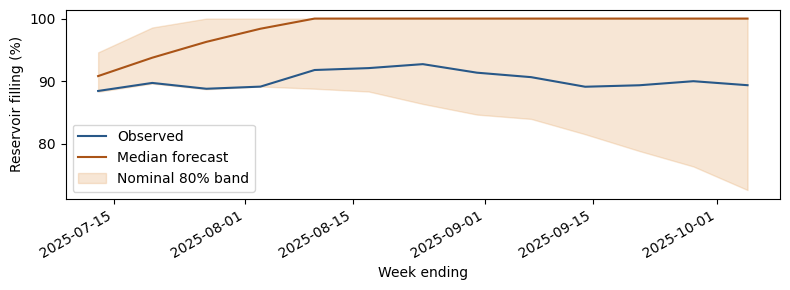

In [6]:
# The held-out dates enter only after selecting settings on the tuning dates.
test_dates = forecast_dates(2025)
holdout = evaluate(test_dates, winner.Order, int(winner.Weeks), winner.Inputs, bands=True)
scored = holdout.dropna(subset=["actual"])
scored_band = scored.dropna(subset=["lower", "upper"])
covered = scored_band.actual.between(scored_band.lower, scored_band.upper)
metrics = pd.DataFrame(
    [scores(scored, "median"), scores(scored, "seasonal_naive")],
    columns=["MAE (pp)", "RMSE (pp)"], index=["SARIMAX", "Seasonal naive"],
)
display(metrics.round(2))
mean_width = (scored_band.upper - scored_band.lower).mean()
print(f"Nominal 80% band: {covered.mean():.1%} coverage across {len(scored_band)} predictions, "
      f"mean width {mean_width:.1f} pp.")
print(f"Historical errors per displayed bound: {scored_band.interval_samples.min()}–"
      f"{scored_band.interval_samples.max()}. "
      f"Median interval-fit runtime: {scored.runtime_ms.median():.1f} ms.")

# Draw the held-out forecast with its uncertainty on the original fill scale.
example = holdout.loc[holdout.origin.eq(test_dates[2])]
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(example.index, example.actual, label="Observed", color="#285888")
ax.plot(example.index, example["median"], label="Median forecast", color="#aa5417")
ax.fill_between(example.index, example.lower, example.upper, alpha=0.22,
                color="#df9142", label="Nominal 80% band")
ax.set(ylabel="Reservoir filling (%)", xlabel="Week ending")
ax.legend(loc="best")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## Map boundaries, transfers, and weather

We export simplified boundaries for the Streamlit map and group NVE regions to approximate the three water areas. We check how temperature and precipitation relate to weekly filling changes and whether weather measured earlier has a stronger relationship. We also compare forecasts with and without weather or net imports on the same dates to see if those inputs help.

In [7]:
# Export and count the map shapes by area type.
geometry_path = root / "data" / "reservoir_areas.geojson"
export_reservoir_geojson(geometry_path)
geometry = json.loads(geometry_path.read_text())
area_types = [feature["properties"]["area_type"] for feature in geometry["features"]]
display(pd.Series(area_types).value_counts())

# Use the same dates and training length to compare optional inputs.
optional_dates = pd.to_datetime(["2025-07-30", "2025-08-27", "2025-09-24"]).tolist()
optional_training_weeks = 78
optional_scores = []
if not flow.empty:
    sources["net_import_mwh"] = flow
    transfer_cases = {
        "NVE only": (),
        f"NVE and {border} net imports": ("net_import_mwh",),
    }
    for name, inputs in transfer_cases.items():
        try:
            forecasts = evaluate(optional_dates, winner.Order, optional_training_weeks, inputs)
        except ValueError as error:
            print(f"{name} could not be scored: {error}")
        else:
            optional_scores.append((name, *scores(forecasts, "median")))
display(pd.DataFrame(optional_scores, columns=["Input comparison", "MAE (pp)", "RMSE (pp)"]).round(2))

EL      5
VASS    3
NO      1
Name: count, dtype: int64

,Input comparison,MAE (pp),RMSE (pp)
0,NVE only,3.96,5.00
1,NVE and NO3–SE2 net imports,3.98,5.11


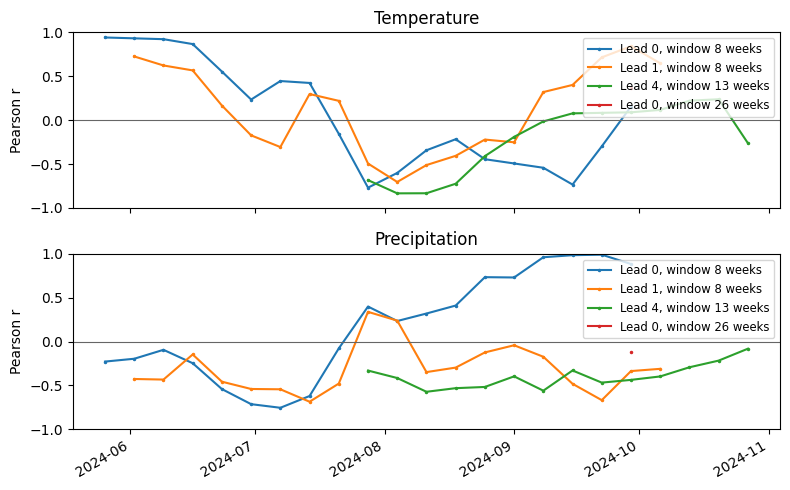

,Weather,Lead,Window,Windows observed,Min r,Max r
0,Temperature,0,8,19,-0.77,0.94
1,Temperature,1,8,19,-0.70,0.84
2,Temperature,4,13,14,-0.83,0.24
3,Temperature,0,26,1,0.37,0.37
4,Precipitation,0,8,19,-0.75,0.99
5,Precipitation,1,8,19,-0.69,0.34
6,Precipitation,4,13,14,-0.57,-0.08
7,Precipitation,0,26,1,-0.11,-0.11


In [8]:
# Use a shorter period to limit the number of weather downloads.
try:
    area_hourly = fetch_weather("NO3", "2024-03-25", "2024-10-01")
    area_weeks = weekly_weather(area_hourly)
except requests.RequestException as error:
    area_weeks = pd.DataFrame()
    print(f"NO3 weather download incomplete ({type(error).__name__}). Cached cells can be reused.")
if not area_weeks.empty:
    fig, axes = plt.subplots(2, 1, figsize=(8, 5), sharex=True, sharey=True)
    summaries = []
    weather_labels = {"temperature_2m": "Temperature", "precipitation": "Precipitation"}
    for ax, (feature, label) in zip(axes, weather_labels.items()):
        for lead, window in [(0, 8), (1, 8), (4, 13), (0, 26)]:
            correlation = rolling_weather_correlation(filling, area_weeks[feature], lead, window).dropna()
            if correlation.empty:
                continue
            ax.plot(correlation.index, correlation,
                    label=f"Lead {lead}, window {window} weeks", marker=".", ms=3)
            summaries.append((label, lead, window, len(correlation), correlation.min(), correlation.max()))
        ax.set(title=label, ylabel="Pearson r", ylim=(-1, 1))
        ax.axhline(0, color="#666", lw=0.8)
        ax.legend(fontsize="small", loc="upper right")
    fig.autofmt_xdate()
    fig.tight_layout()
    plt.show()
    correlation_summary = pd.DataFrame(summaries,
        columns=["Weather", "Lead", "Window", "Windows observed", "Min r", "Max r"])
    display(correlation_summary.round(2))

In [9]:
# Reuse the weekly weather cache to avoid rebuilding the training history.
first, last = pd.Timestamp("2024-01-21"), pd.Timestamp("2025-09-21")
weather_cache = root / ".local" / "part4-weather-training.csv"
try:
    if weather_cache.is_file():
        weather_fit = pd.read_csv(weather_cache, index_col="week", parse_dates=["week"])
        weather_fit["available_at"] = pd.to_datetime(weather_fit.available_at, utc=True)
    else:
        blocks = [
            (first, pd.Timestamp("2024-12-29")),
            (pd.Timestamp("2025-01-05"), last),
        ]
        weather_fit = pd.concat([weather_week_range("NO3", a, b) for a, b in blocks])
        weather_fit.to_csv(weather_cache)
    weather_inputs = ("temperature_2m", "precipitation")
    for feature in weather_inputs:
        sources[feature] = weather_fit

    comparison = []
    for inputs in [(), weather_inputs]:
        forecasts = evaluate(optional_dates, winner.Order, optional_training_weeks, inputs)
        label = " + ".join(inputs) or "NVE only"
        comparison.append((label, *scores(forecasts, "median")))
    display(pd.DataFrame(comparison, columns=["Inputs", "MAE (pp)", "RMSE (pp)"]).round(2))
except (requests.RequestException, ValueError) as error:
    print(f"Optional weather comparison could not run for {first.date()} through {last.date()}.")
    print(type(error).__name__, "· Cached ERA5 cells are reused on the next run.")

,Inputs,MAE (pp),RMSE (pp)
0,NVE only,3.96,5.00
1,temperature_2m + precipitation,4.07,5.16


## Compulsory work log

I started by sketching the three Streamlit pages. Map & Overview and Forecast share the selected area, history dates, and forecast horizon, while Explore & Quality shares the area and keeps its own analysis controls. Putting the historical chart beside the NVE table made it easier to check an unusual value in the original records. The map labels the water areas as approximations because they are made from groups of NVE administrative regions, which also affect the weather averages.

In Jupyter, I checked how each source records time before joining the data. NVE publishes filling figures after the week ends, ENTSO-E uses UTC intervals, ERA5 precipitation is recorded for the previous hour, and Norges Bank publishes exchange rates on business days. The Easter example helped me check the clock change and missing holiday quotes. I used estimated release times to decide which data each forecast could use, since historical data can include later revisions.

I tested 13-week forecasts from several past dates and compared their errors and runtimes. On the 2025 test dates, SARIMAX had a mean absolute error of 8.94 percentage points. Using filling from the same week a year earlier gave 16.72. Streamlit uses 104 weeks of history, SARIMAX order (2, 1, 1), seasonal order (1, 0, 0, 52), and both exchange rates. I used River's quantile loss on past errors to estimate the 80% prediction band. The band contained 86.5% of the 52 test observations and averaged 26.7 percentage points wide.

In the notebook, I could compare weather lags and see how often the forecast band covered observations. For NO3 in 2024, the 8-week temperature correlation ranged from −0.77 to 0.94 with no lag, while the 26-week window gave only one estimate. That made it worth comparing forecast errors on the same dates to see whether weather helped. In Streamlit, I needed clear chart labels, messages for missing data, and controls that keep their values between pages. Caching made it quicker to try different dates without downloading the weather files again.

[Public GitHub repository](https://github.com/dared22/ind320) ·
[Streamlit app](https://cklqlkatpe9mqyrnuch2ma.streamlit.app/)

## AI-tool use

I used Codex to help write the data-loading code, align dates, test the forecasts, and build the Streamlit pages. It also helped with tests and the notebook export. I am responsible for checking the assumptions and explaining the results.